## Máster en Big Data y Data Science

### Metodologías de gestión y diseño de proyectos de big data

#### AP2 - Modelado y evaluación

---

En esta libreta se realiza la experimentación para generación del modelo de predicción objetivo del proyecto y la evaluación del mismo.
La versión del dataset a utilizar es la obtenida a partir de las operaciones de transformación.

---
En esta version de la libreta se va incorporar el registro de los detalles de la experimentacionn con la libreria MLFLOW

In [1]:
# Se importan las librerías necesarias y se suprimen las advertencias
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore',category=FutureWarning)
warnings.filterwarnings('ignore',category=UserWarning)

### Se agrega la libreria mlflow y configuracion

In [2]:
import mlflow
import mlflow.sklearn
from pathlib import Path

# Directorio raíz del proyecto
PROJECT_DIR = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "pyproject.toml").exists()),
    None
)

if PROJECT_DIR is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")

# Base de datos SQLite
MLFLOW_DB = PROJECT_DIR / "mlflow.db"

# Configuración de MLflow
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB.as_posix()}")

EXPERIMENT_NAME = "Proyecto 13MBID-ABR2627 - Experimentacion original"

mlflow.set_experiment(EXPERIMENT_NAME)

print("Proyecto:", PROJECT_DIR)
print("Base de datos:", MLFLOW_DB)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento:", mlflow.get_experiment_by_name(EXPERIMENT_NAME))

Proyecto: c:\Users\Alonso Cuadros Román\Desktop\PORTAFOLIO\13MBID-ABR2627
Base de datos: c:\Users\Alonso Cuadros Román\Desktop\PORTAFOLIO\13MBID-ABR2627\mlflow.db
Tracking URI: sqlite:///c:/Users/Alonso Cuadros Román/Desktop/PORTAFOLIO/13MBID-ABR2627/mlflow.db
Experimento: <Experiment: artifact_location=('file:c:/Users/Alonso Cuadros '
 'Román/Desktop/PORTAFOLIO/13MBID-ABR2627/notebooks/mlruns/1'), creation_time=1793593294833, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793593294833, lifecycle_stage='active', name='Proyecto 13MBID-ABR2627 - Experimentacion original', tags={}, trace_location=None, workspace='default'>


In [3]:
# Lectura de los datos
df = pd.read_csv('../data/processed/bank-processed.csv')
df.head(5)

,age,job,marital,education,housing,loan,contact,month,day_of_week,duration,...,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y,age_group,previously_contacted,campaign_group
0,56,housemaid,married,basic.4y,no,no,telephone,may,mon,261,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,51-65,0,1
1,57,services,married,high.school,no,no,telephone,may,mon,149,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,51-65,0,1
2,37,services,married,high.school,yes,no,telephone,may,mon,226,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,36-50,0,1
3,40,admin.,married,basic.6y,no,no,telephone,may,mon,151,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,36-50,0,1
4,56,services,married,high.school,no,yes,telephone,may,mon,307,...,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,51-65,0,1


In [4]:
# Se divide el dataset en variables predictoras y variable objetivo
X = df.drop('y', axis=1)
y = df['y']

In [5]:
# Se genera el conjunto de entrenamiento y prueba con estratificación
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [6]:
# Se separan las columnas numéricas
numerical_columns=X_train.select_dtypes(exclude='object').columns
display(numerical_columns)

categorical_columns=X_train.select_dtypes(include='object').columns
display(categorical_columns)

Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp_var_rate',
       'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed',
       'previously_contacted'],
      dtype='object')

Index(['job', 'marital', 'education', 'housing', 'loan', 'contact', 'month',
       'day_of_week', 'poutcome', 'age_group', 'campaign_group'],
      dtype='object')

In [7]:
# Se verifica la distribución de la variable objetivo en el conjunto de entrenamiento
y_train.value_counts()

y
0    29228
1     3711
Name: count, dtype: int64

In [8]:
# Se crea un pipeline para preprocesamiento de datos
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler  

# Pipeline para valores numéricos
num_pipeline = Pipeline(steps=[
    ('RobustScaler', RobustScaler())
])

# Pipeline para valores categóricos
cat_pipeline = Pipeline(steps=[
    ('OneHotEncoder', OneHotEncoder(drop='first',sparse_output=False))
])

# Se configuran los preprocesadores
preprocessor_full = ColumnTransformer([
    ('num_pipeline', num_pipeline, numerical_columns),
    ('cat_pipeline', cat_pipeline, categorical_columns)
]).set_output(transform='pandas')

In [9]:
preprocessor_train_valid = ColumnTransformer([
    ('num_pipeline', num_pipeline, numerical_columns),
    ('cat_pipeline', cat_pipeline, categorical_columns)
]).set_output(transform='pandas')

In [10]:
# Se ajusta y transforma el conjunto de entrenamiento y prueba
x_train_prep = preprocessor_full.fit_transform(X_train)
x_test_prep = preprocessor_full.transform(X_test)

In [11]:
# Se aplica submuestreo a los datos preprocesados
from sklearn.utils import resample

# Combinar los datos preprocesados con las etiquetas
train_data = x_train_prep.copy()
train_data['target'] = y_train.reset_index(drop=True)

# Separar por clase
class_0 = train_data[train_data['target'] == 0]
class_1 = train_data[train_data['target'] == 1]

# Encontrar la clase minoritaria
min_count = min(len(class_0), len(class_1))

# Submuestreo balanceado - tomar una muestra igual al tamaño de la clase minoritaria
class_0_balanced = resample(class_0, n_samples=min_count, random_state=42)
class_1_balanced = resample(class_1, n_samples=min_count, random_state=42)

# Combinar las clases balanceadas
balanced_data = pd.concat([class_0_balanced, class_1_balanced])

# Separar características y objetivo
x_train_resampled = balanced_data.drop('target', axis=1)
y_train_resampled = balanced_data['target']

print(f"Tamaño original: {len(x_train_prep)}")
print(f"Tamaño balanceado: {len(x_train_resampled)}")
print(f"Distribución balanceada: {y_train_resampled.value_counts()}")

Tamaño original: 32939
Tamaño balanceado: 5934
Distribución balanceada: target
0.0    2967
1.0    2967
Name: count, dtype: int64


-----
## Este apartado se va cambiar

In [11]:
from sklearn.model_selection import cross_val_score


# Se genera una función para realizar validación cruzada
def cross_val(model):
    scores = cross_val_score(model,x_train_resampled , y_train_resampled, cv=5, scoring='f1')
    print('cross validation f1 scores',scores*100)
    print('cross validation f1 mean',scores.mean()*100)
    print('cross validation f1 std',scores.std())
    print('-'*50)
    scores = cross_val_score(model,x_train_resampled , y_train_resampled, cv=5, scoring='recall')
    print('cross validation recall scores',scores*100)
    print('cross validation recall mean',scores.mean()*100)
    print('cross validation recall std',scores.std())

-------
### El cambio consiste en qe la funcion directamente registre los detalles de la experimentacion en mlflow

In [18]:
import mlflow
import mlflow.sklearn

import pandas as pd

from mlflow.models import infer_signature

from sklearn.model_selection import cross_val_score

from sklearn.metrics import (
    f1_score,
    recall_score,
    precision_score,
    accuracy_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import LinearSVC

# Nuevos algoritmos
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.naive_bayes import GaussianNB


def cross_val_mlflow(model, model_name, params=None):
    """
    Realiza validación cruzada y registra los resultados en MLflow.
    """

    with mlflow.start_run(run_name=model_name):

        # Validación cruzada: F1
        f1_scores = cross_val_score(
            model,
            x_train_resampled,
            y_train_resampled,
            cv=5,
            scoring='f1'
        )
        f1_mean = f1_scores.mean()
        f1_std = f1_scores.std()

        # Validación cruzada: Recall
        recall_scores = cross_val_score(
            model,
            x_train_resampled,
            y_train_resampled,
            cv=5,
            scoring='recall'
        )
        recall_mean = recall_scores.mean()
        recall_std = recall_scores.std()

        # Validación cruzada: Precision
        precision_scores = cross_val_score(
            model,
            x_train_resampled,
            y_train_resampled,
            cv=5,
            scoring='precision'
        )
        precision_mean = precision_scores.mean()
        precision_std = precision_scores.std()

        # Validación cruzada: Accuracy
        accuracy_scores = cross_val_score(
            model,
            x_train_resampled,
            y_train_resampled,
            cv=5,
            scoring='accuracy'
        )
        accuracy_mean = accuracy_scores.mean()
        accuracy_std = accuracy_scores.std()

        # Entrenamiento final
        model.fit(x_train_resampled, y_train_resampled)

        # Predicciones
        y_pred = model.predict(x_test_prep)

        # Firma del modelo
        signature = infer_signature(x_test_prep, y_pred)

        # Métricas del conjunto de prueba
        test_f1 = f1_score(y_test, y_pred, zero_division=0)
        test_recall = recall_score(y_test, y_pred, zero_division=0)
        test_precision = precision_score(y_test, y_pred, zero_division=0)
        test_accuracy = accuracy_score(y_test, y_pred)

        # Registro de parámetros
        if params is not None:
            mlflow.log_params(params)
        else:
            mlflow.log_params(model.get_params())

        mlflow.log_params({
            "train_samples": len(x_train_resampled),
            "test_samples": len(x_test_prep),
            "balancing_method": "undersampling",
            "cv_folds": 5
        })

        # Registro de métricas de validación cruzada
        mlflow.log_metrics({
            "cv_f1_mean": f1_mean,
            "cv_f1_std": f1_std,
            "cv_recall_mean": recall_mean,
            "cv_recall_std": recall_std,
            "cv_precision_mean": precision_mean,
            "cv_precision_std": precision_std,
            "cv_accuracy_mean": accuracy_mean,
            "cv_accuracy_std": accuracy_std
        })

        # Registro de métricas de prueba
        mlflow.log_metrics({
            "test_f1": test_f1,
            "test_recall": test_recall,
            "test_precision": test_precision,
            "test_accuracy": test_accuracy
        })

        # Registro del modelo en MLflow
        mlflow.sklearn.log_model(
            model,
            name="model",
            signature=signature,
            skops_trusted_types=["sklearn.tree._tree.Tree"]
        )

        # ID de ejecución
        run_id = mlflow.active_run().info.run_id

        print(
            f"Modelo {model_name} registrado en MLflow "
            f"con ID de ejecución: {run_id}"
        )

    return model, {
        "cv_f1_mean": f1_mean,
        "cv_recall_mean": recall_mean,
        "cv_precision_mean": precision_mean,
        "cv_accuracy_mean": accuracy_mean,
        "test_f1": test_f1,
        "test_recall": test_recall,
        "test_precision": test_precision,
        "test_accuracy": test_accuracy
    }


----
Se cambian esta celda que hacen todas las llamadas

In [12]:
# Se aplica un modelo de regresión logística
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(C=1,penalty='l2',solver='liblinear',random_state=1,max_iter=100,tol=0.000000001)

# cross validation scores
cross_val(lr)

cross validation f1 scores [51.61825726 53.42349958 53.33333333 56.42737896 52.09222886]
cross validation f1 mean 53.37893960025001
cross validation f1 std 0.016764650249772996
--------------------------------------------------
cross validation recall scores [52.44519393 53.28836425 55.21885522 56.9023569  51.43338954]
cross validation recall mean 53.857631968930455
cross validation recall std 0.01965669195989469


In [13]:
# LinearSVC
from sklearn.svm import LinearSVC
svc = LinearSVC(max_iter=10000,tol=0.001)

# cross validation scores
cross_val(svc)

cross validation f1 scores [51.32013201 53.24347094 52.77777778 56.23960067 51.75064048]
cross validation f1 mean 53.066324373978155
cross validation f1 std 0.017300019849346267
--------------------------------------------------
cross validation recall scores [52.44519393 53.28836425 54.37710438 56.9023569  51.09612142]
cross validation recall mean 53.62182817494791
cross validation recall std 0.019599577464980426


In [14]:
# knclassifier
from sklearn.neighbors import KNeighborsClassifier
knc = KNeighborsClassifier(n_neighbors=7)

# cross validation scores
cross_val(knc)

cross validation f1 scores [58.62348178 56.64451827 60.17418844 57.63265306 57.14285714]
cross validation f1 mean 58.04353973962101
cross validation f1 std 0.012500651763359032
--------------------------------------------------
cross validation recall scores [61.0455312  57.50421585 63.97306397 59.42760943 58.6846543 ]
cross validation recall mean 60.12701494994918
cross validation recall std 0.02239839843553927


In [15]:
# decision tree classifier
from sklearn.tree import DecisionTreeClassifier
tree=DecisionTreeClassifier()

# cross validation scores
cross_val(tree)

cross validation f1 scores [70.23144453 69.68973747 70.64364207 72.02572347 70.09646302]
cross validation f1 mean 70.53740211413559
cross validation f1 std 0.008041094536813731
--------------------------------------------------
cross validation recall scores [75.88532884 73.693086   73.90572391 74.24242424 73.18718381]
cross validation recall mean 74.18274935981512
cross validation recall std 0.009176058012429265


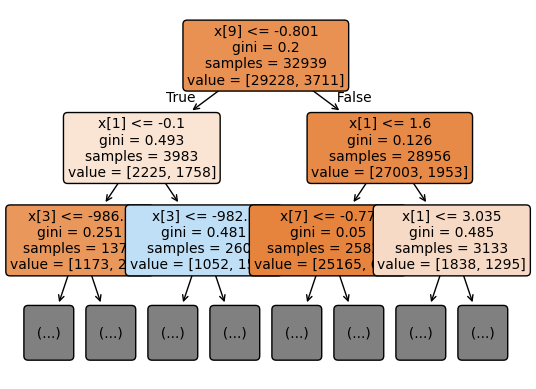

In [16]:
# decision tree plot
from sklearn.tree import plot_tree
tree.fit(x_train_prep, y_train)
plot_tree(tree, filled=True, rounded=True,max_depth=2,fontsize=10)
plt.show()

In [17]:
# Se obtiene la matriz de confusión para el modelo
from sklearn.metrics import confusion_matrix

y_pred = tree.predict(x_test_prep)
cm = confusion_matrix(y_test, y_pred)
print(cm)


[[6824  483]
 [ 440  488]]


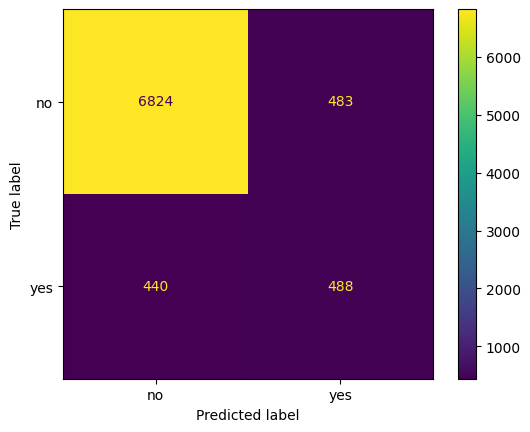

In [18]:
# Se visualiza la matriz de confusión
from sklearn.metrics import ConfusionMatrixDisplay
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['no', 'yes'])
disp.plot()

----
### Esta es la nueva celda que hace la invocacion al proceso con mlflow

In [19]:

# Resultados
resultados = {}


# ==========================================
# MÉTODO 1: LOGISTIC REGRESSION
# ==========================================

lr = LogisticRegression(
    C=1,
    penalty="l2",
    solver="liblinear",
    random_state=1,
    max_iter=100,
    tol=0.000000001
)

model_lr, metrics_lr = cross_val_mlflow(
    lr, "Logistic Regression"
)

resultados["Logistic Regression"] = metrics_lr


# ==========================================
# MÉTODO 2: LINEAR SVC
# ==========================================

svc = LinearSVC(
    max_iter=10000,
    tol=0.001,
    random_state=42
)

model_svc, metrics_svc = cross_val_mlflow(
    svc, "Linear SVC"
)

resultados["Linear SVC"] = metrics_svc


# ==========================================
# MÉTODO 3: K-NEAREST NEIGHBORS
# ==========================================

knc = KNeighborsClassifier(
    n_neighbors=7
)

model_knc, metrics_knc = cross_val_mlflow(
    knc, "K-Nearest Neighbors"
)

resultados["K-Nearest Neighbors"] = metrics_knc


# ==========================================
# MÉTODO 4: DECISION TREE
# ==========================================

tree = DecisionTreeClassifier(
    random_state=42
)

model_tree, metrics_tree = cross_val_mlflow(
    tree, "Decision Tree Classifier"
)

resultados["Decision Tree Classifier"] = metrics_tree


# ==========================================
# MÉTODO 5: RANDOM FOREST
# ==========================================

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

model_rf, metrics_rf = cross_val_mlflow(
    rf, "Random Forest"
)

resultados["Random Forest"] = metrics_rf


# ==========================================
# MÉTODO 6: GRADIENT BOOSTING
# ==========================================

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

model_gb, metrics_gb = cross_val_mlflow(
    gb, "Gradient Boosting"
)

resultados["Gradient Boosting"] = metrics_gb


# ==========================================
# MÉTODO 7: GAUSSIAN NAIVE BAYES
# ==========================================

nb = GaussianNB()

model_nb, metrics_nb = cross_val_mlflow(
    nb, "Gaussian Naive Bayes"
)

resultados["Gaussian Naive Bayes"] = metrics_nb


2026/11/02 01:18:47 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo Logistic Regression registrado en MLflow con ID de ejecución: b53fed7acf6b4747bbe2ad00eb9019e2


2026/11/02 01:19:02 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo Linear SVC registrado en MLflow con ID de ejecución: fe993eb3c4b84e14b38a67af8a08ec17


2026/11/02 01:19:19 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo K-Nearest Neighbors registrado en MLflow con ID de ejecución: 19799c9848d74394bc6b8fc075b2504f


... (4 outputs left out)

2026/11/02 01:20:38 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo Gradient Boosting registrado en MLflow con ID de ejecución: 131cdcd38ff24903a1427b166d3e7c21


2026/11/02 01:20:53 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo Gaussian Naive Bayes registrado en MLflow con ID de ejecución: ebdfa356805e4906b8196d0a176344fa


In [20]:
import mlflow
from mlflow.tracking import MlflowClient

print("Tracking URI:", mlflow.get_tracking_uri())

client = MlflowClient()

experimentos = client.search_experiments()

for exp in experimentos:
    print(
        "Nombre:", exp.name,
        "| ID:", exp.experiment_id,
        "| Estado:", exp.lifecycle_stage
    )

Tracking URI: sqlite:///c:/Users/Alonso Cuadros Román/Desktop/PORTAFOLIO/13MBID-ABR2627/mlflow.db
Nombre: Proyecto 13MBID-ABR2627 - Experimentacion original | ID: 1 | Estado: active
Nombre: Default | ID: 0 | Estado: active


----
A continuacion se realiza una comparacion de los modelos para seleccionar el que va ser el utilizado posteriormente

In [27]:

# Crear DataFrame con los resultados de los modelos
df_comparacion = pd.DataFrame(resultados).T

# Redondear métricas a 4 decimales
df_comparacion = df_comparacion.round(4)

# Ordenar por F1 Score del conjunto de prueba
df_comparacion = df_comparacion.sort_values(
    by="test_f1",
    ascending=False
)

# Mostrar resultados
print(df_comparacion)

# Identificar el mejor modelo
print("El mejor modelo según F1 en el conjunto de prueba es:",df_comparacion.index[0])
print(f"Valor de F1 en test: {df_comparacion.iloc[0]['test_f1']}")
print(f"Valor de Recall en test: {df_comparacion.iloc[0]['test_recall']}")


                          cv_f1_mean  cv_recall_mean  cv_precision_mean  \
Linear SVC                    0.5307          0.5362             0.5255   
Logistic Regression           0.5338          0.5386             0.5294   
K-Nearest Neighbors           0.5804          0.6013             0.5612   
Gaussian Naive Bayes          0.6464          0.8995             0.5053   
Decision Tree Classifier      0.7037          0.7438             0.6677   
Random Forest                 0.7038          0.6963             0.7121   
Gradient Boosting             0.5907          0.6161             0.5674   

                          cv_accuracy_mean  test_f1  test_recall  \
Linear SVC                          0.5258   0.1989       0.5614   
Logistic Regression                 0.5297   0.1966       0.5517   
K-Nearest Neighbors                 0.5657   0.1936       0.5086   
Gaussian Naive Bayes                0.5096   0.1847       0.8351   
Decision Tree Classifier            0.6867   0.1476       0

In [ ]:

# Resultados
resultados = {}


# ==========================================
# MÉTODO 1: LOGISTIC REGRESSION
# ==========================================

lr = LogisticRegression(
    C=1,
    penalty="l2",
    solver="liblinear",
    random_state=1,
    max_iter=100,
    tol=0.000000001
)

model_lr, metrics_lr = cross_val_mlflow(
    lr, "Logistic Regression"
)

resultados["Logistic Regression"] = metrics_lr


# ==========================================
# MÉTODO 2: LINEAR SVC
# ==========================================

svc = LinearSVC(
    max_iter=10000,
    tol=0.001,
    random_state=42
)

model_svc, metrics_svc = cross_val_mlflow(
    svc, "Linear SVC"
)

resultados["Linear SVC"] = metrics_svc


# ==========================================
# MÉTODO 3: K-NEAREST NEIGHBORS
# ==========================================

knc = KNeighborsClassifier(
    n_neighbors=7
)

model_knc, metrics_knc = cross_val_mlflow(
    knc, "K-Nearest Neighbors"
)

resultados["K-Nearest Neighbors"] = metrics_knc


# ==========================================
# MÉTODO 4: DECISION TREE
# ==========================================

tree = DecisionTreeClassifier(
    random_state=42
)

model_tree, metrics_tree = cross_val_mlflow(
    tree, "Decision Tree Classifier"
)

resultados["Decision Tree Classifier"] = metrics_tree


# ==========================================
# MÉTODO 5: RANDOM FOREST
# ==========================================

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)

model_rf, metrics_rf = cross_val_mlflow(
    rf, "Random Forest"
)

resultados["Random Forest"] = metrics_rf


# ==========================================
# MÉTODO 6: GRADIENT BOOSTING
# ==========================================

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

model_gb, metrics_gb = cross_val_mlflow(
    gb, "Gradient Boosting"
)

resultados["Gradient Boosting"] = metrics_gb


# ==========================================
# MÉTODO 7: GAUSSIAN NAIVE BAYES
# ==========================================

nb = GaussianNB()

model_nb, metrics_nb = cross_val_mlflow(
    nb, "Gaussian Naive Bayes"
)

resultados["Gaussian Naive Bayes"] = metrics_nb


2026/11/02 01:18:47 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo Logistic Regression registrado en MLflow con ID de ejecución: b53fed7acf6b4747bbe2ad00eb9019e2


2026/11/02 01:19:02 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo Linear SVC registrado en MLflow con ID de ejecución: fe993eb3c4b84e14b38a67af8a08ec17


2026/11/02 01:19:19 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo K-Nearest Neighbors registrado en MLflow con ID de ejecución: 19799c9848d74394bc6b8fc075b2504f


2026/11/02 01:19:36 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo Decision Tree Classifier registrado en MLflow con ID de ejecución: 806a2a469b8d43c3ab872e1b3bd3a539


2026/11/02 01:20:02 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Modelo Random Forest registrado en MLflow con ID de ejecución: 923d2c38b9464a52bea8c5f8ff8081da


#### Predicción con datos nuevos (sin clasificar)

In [25]:
df_nuevos = pd.read_csv('../data/raw/bank-additional-new.csv')
df_nuevos.head(5)

,age,job,marital,education,housing,loan,contact,month,day_of_week,duration,campaign,previous,poutcome,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y,contacted_before
0,56,housemaid,married,basic.4y,no,no,telephone,may,mon,261,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,NaN
1,57,services,married,high.school,no,no,telephone,may,mon,149,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,NaN
2,37,services,married,high.school,yes,no,telephone,may,mon,226,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,NaN
3,40,admin.,married,basic.6y,no,no,telephone,may,mon,151,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,NaN
4,56,services,married,high.school,no,yes,telephone,may,mon,307,1,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,NaN


In [26]:
# Diagnosticar el problema con los nuevos datos
print("Información del conjunto de datos nuevos:")
print(f"Forma: {df_nuevos.shape}")
print("\nTipos de datos:")
print(df_nuevos.dtypes)
print("\nValores nulos:")
print(df_nuevos.isnull().sum())
print("\nColumnas categóricas en nuevos datos:")
print(df_nuevos.select_dtypes(include='object').columns.tolist())
print("\nColumnas numéricas en nuevos datos:")
print(df_nuevos.select_dtypes(exclude='object').columns.tolist())

Información del conjunto de datos nuevos:
Forma: (9, 20)

Tipos de datos:
age                   int64
job                  object
marital              object
education            object
housing              object
loan                 object
contact              object
month                object
day_of_week          object
duration              int64
campaign              int64
previous              int64
poutcome             object
emp_var_rate        float64
cons_price_idx      float64
cons_conf_idx       float64
euribor3m           float64
nr_employed         float64
y                    object
contacted_before    float64
dtype: object

Valores nulos:
age                 0
job                 0
marital             0
education           0
housing             0
loan                0
contact             0
month               0
day_of_week         0
duration            0
campaign            0
previous            0
poutcome            0
emp_var_rate        0
cons_price_idx      0
cons_c

In [27]:
# Comparar con los datos de entrenamiento originales
print("Comparación de columnas:")
print(f"Columnas en datos originales: {list(X.columns)}")
print(f"Columnas en datos nuevos: {list(df_nuevos.columns)}")

print("\nColumnas que están en nuevos pero no en originales:")
new_cols = set(df_nuevos.columns) - set(X.columns)
print(new_cols)

print("\nColumnas que están en originales pero no en nuevos:")
missing_cols = set(X.columns) - set(df_nuevos.columns)
print(missing_cols)

Comparación de columnas:
Columnas en datos originales: ['age', 'job', 'marital', 'education', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'age_group', 'previously_contacted', 'campaign_group']
Columnas en datos nuevos: ['age', 'job', 'marital', 'education', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'previous', 'poutcome', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'y', 'contacted_before']

Columnas que están en nuevos pero no en originales:
{'y', 'contacted_before'}

Columnas que están en originales pero no en nuevos:
{'campaign_group', 'previously_contacted', 'age_group', 'pdays'}


In [24]:
# Se hace la predicción con los nuevos datos
# Primero, eliminar la columna objetivo si existe y preparar las características
X_new = df_nuevos.drop('y', axis=1) if 'y' in df_nuevos.columns else df_nuevos.copy()

# Asegurar que las columnas estén en el mismo orden que en el entrenamiento
#X_new = X_new[X.columns]

# Manejar la columna contacted_before para que coincida con el formato de entrenamiento
# En entrenamiento: 'no', 'yes' (string)
# En nuevos datos: NaN -> necesita convertirse a 'no' (asumiendo que NaN significa no contactado)
X_new['contacted_before'] = X_new['contacted_before'].fillna('no')

# Convertir cualquier valor numérico a string si es necesario
if X_new['contacted_before'].dtype in ['float64', 'int64']:
    X_new['contacted_before'] = X_new['contacted_before'].map({0.0: 'no', 1.0: 'yes'}).fillna('no')

# Asegurar que contacted_before sea de tipo object como en entrenamiento
X_new['contacted_before'] = X_new['contacted_before'].astype('object')

# Transformar los nuevos datos usando el mismo preprocesador y predecir
try:
    x_new_prep = preprocessor_full.transform(X_new)
    
    y_new_pred = tree.predict(x_new_prep)
    print(f"\nPredicciones: {y_new_pred}")
    
    predictions_df = pd.DataFrame({
        'Cliente': range(1, len(y_new_pred) + 1),
        'Predicción_Numérica': y_new_pred,
        'Suscribirá': ['No' if pred == 0 else 'Sí' for pred in y_new_pred]
    })
    print("\nResultados detallados:")
    print(predictions_df.to_string(index=False))
    
    # Resumen de predicciones
    pred_counts = pd.Series(y_new_pred).value_counts()
    print("\nResumen de predicciones:")
    for pred_val, count in pred_counts.items():
        label = 'No realizará un depósito' if pred_val == 0 else 'Sí realizará un depósito'
        print(f"  {label}: {count} clientes ({count/len(y_new_pred)*100:.1f}%)")
    
except Exception as e:
    print(f"Error durante el preprocesamiento o predicción: {e}")
    print("Información adicional para depuración:")
    print(f"Tipos de datos en X_new:\n{X_new.dtypes}")

Error durante el preprocesamiento o predicción: columns are missing: {'campaign_group', 'previously_contacted', 'age_group', 'pdays'}
Información adicional para depuración:
Tipos de datos en X_new:
age                   int64
job                  object
marital              object
education            object
housing              object
loan                 object
contact              object
month                object
day_of_week          object
duration              int64
campaign              int64
previous              int64
poutcome             object
emp_var_rate        float64
cons_price_idx      float64
cons_conf_idx       float64
euribor3m           float64
nr_employed         float64
contacted_before     object
dtype: object
